<a href="https://colab.research.google.com/github/Wapikkk/text-summarize-nlp/blob/data/notebooks/01_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Install Package**

In [1]:
!pip install -q pandas pyarrow

## **Import Package**

In [2]:
import pandas as pd
import re, numpy as np
import matplotlib.pyplot as plt
import os, json
import os

from google.colab import files
from google.colab import drive

url = "https://huggingface.co/datasets/esdurmus/wiki_lingua/resolve/main/indonesian/train-00000-of-00001.parquet"
df = pd.read_parquet(url)

print(df.shape)
print(df.columns)

(16308, 2)
Index(['url', 'article'], dtype='object')


In [3]:
art = df["article"].iloc[0]
print(art.keys())
print("jumlah bagian:", len(art["document"]))
print(art["section_name"][0])
print(art["document"][0][:300])


dict_keys(['section_name', 'document', 'summary', 'english_url', 'english_section_name'])
jumlah bagian: 2
Menghitung Pengembalian Disetahunkan
Jika tingkat pengembalian total telah dihitung, masukkan hasilnya ke persamaan berikut: Pengembalian Disetahunkan=(1+ Pengembalian)1/N-1 Hasil persamaan ini sesuai dengan pengembalian investasi setiap tahunnya selama rentang waktu yang diukur.  Di dalam eksponen (pangkat), angka “1” mencerminkan uni


In [4]:
rows = []
tidak_cocok = 0
for i, art in enumerate(df["article"]):
    n_doc, n_sum, n_name = len(art["document"]), len(art["summary"]), len(art["section_name"])
    if not (n_doc == n_sum == n_name):
        tidak_cocok += 1
        continue
    for j in range(n_doc):
        rows.append({
            "article_id": i,
            "section_id": j,
            "section_name": art["section_name"][j],
            "document": art["document"][j],
            "summary": art["summary"][j],
        })

sec = pd.DataFrame(rows)
print(len(df), "artikel ->", len(sec), "bagian")
print("artikel dengan jumlah list tidak sama:", tidak_cocok)
sec.head()

16308 artikel -> 47481 bagian
artikel dengan jumlah list tidak sama: 0


,article_id,section_id,section_name,document,summary
0,0,0,Menghitung Pengembalian Disetahunkan,Jika tingkat pengembalian total telah dihitung...,Hitunglah pengembalian disetahunkan Anda. Hitu...
1,0,1,Memahami Dasar-Dasar Perhitungan,Saat mendiskusikan pengembalian portofolio tah...,Ketahui istilah-istilah kunci. Pelajari cara k...
2,1,0,Mengikat Pita secara Diagonal,Sisakan sekitar 10-20 cm pita menggantung di s...,Bentangkan pita di sepanjang sudut kiri atas k...
3,1,1,Mengikat Pita Standar,Sisakan sekitar 10-20 cm pita menggantung di s...,Bentangkan pita secara horizontal di sepanjang...
4,1,2,Membuat Tampilan Anyam,"Untuk tampilan unik, pertimbangkan memakai dua...",Potong empat utas pita yang cukup panjang diba...


          doc_words     sum_words         ratio
count  47481.000000  47481.000000  4.748100e+04
mean     346.915503     30.782818           inf
std      222.825798     18.250683           NaN
min        0.000000      1.000000  4.385965e-03
25%      190.000000     19.000000  5.579399e-02
50%      304.000000     27.000000  8.639309e-02
75%      456.000000     39.000000  1.428571e-01
max     2728.000000    292.000000           inf

bagian per artikel:
count    16308.000000
mean         2.911516
std          1.040639
min          1.000000
25%          2.000000
50%          3.000000
75%          3.000000
max         19.000000
dtype: float64

document kosong: 7
summary kosong: 0
duplikat (document+summary): 1
document sama dalam satu artikel: 3


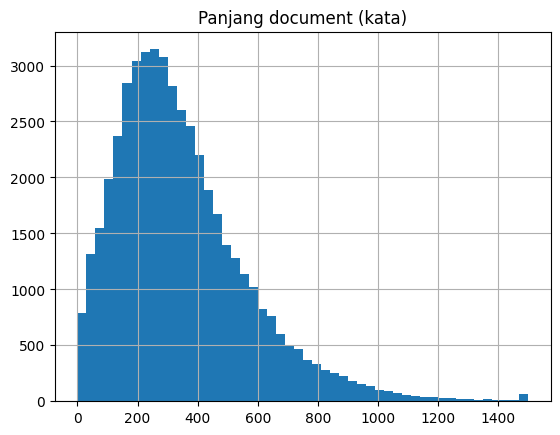

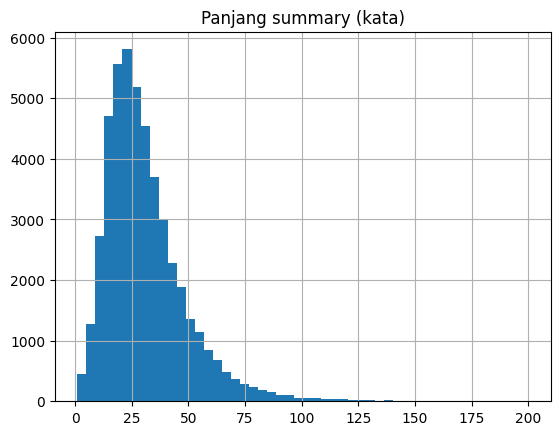

In [5]:


sec["doc_words"] = sec["document"].str.split().str.len()
sec["sum_words"] = sec["summary"].str.split().str.len()
sec["ratio"] = sec["sum_words"] / sec["doc_words"]

print(sec[["doc_words", "sum_words", "ratio"]].describe())
print("\nbagian per artikel:")
print(sec.groupby("article_id").size().describe())
print("\ndocument kosong:", (sec["document"].str.strip() == "").sum())
print("summary kosong:", (sec["summary"].str.strip() == "").sum())
print("duplikat (document+summary):", sec.duplicated(["document", "summary"]).sum())
print("document sama dalam satu artikel:", sec.duplicated(["article_id", "document"]).sum())

plt.figure(); sec["doc_words"].clip(upper=1500).hist(bins=50); plt.title("Panjang document (kata)"); plt.show()
plt.figure(); sec["sum_words"].clip(upper=200).hist(bins=50); plt.title("Panjang summary (kata)"); plt.show()

In [6]:


def clean(t):
    t = t.replace("\u200b", "").replace("\ufeff", "").replace("\xa0", " ")
    return re.sub(r"\s+", " ", t).strip()   # tidak lowercase

# cek cuplikan sebelum dan sesudah
for k in [0, 1, 2]:
    print("SEBELUM:", repr(sec["document"].iloc[k][:200]))
    print("SESUDAH:", repr(clean(sec["document"].iloc[k])[:200]))
    print()

data = sec.copy()
data["document"] = data["document"].map(clean)
data["summary"] = data["summary"].map(clean)
n0 = len(data)
data = data[(data["document"] != "") & (data["summary"] != "")]
data = data.drop_duplicates(["document", "summary"])
print("dibuang:", n0 - len(data), "dari", n0)

data["id"] = data["article_id"].astype(str) + "_" + data["section_id"].astype(str)

# split per artikel, seed 42, rasio 80/10/10
ids = data["article_id"].unique()
np.random.default_rng(42).shuffle(ids)
n = len(ids)
train_ids = set(ids[:int(0.8 * n)])
val_ids = set(ids[int(0.8 * n):int(0.9 * n)])

train = data[data["article_id"].isin(train_ids)]
val = data[data["article_id"].isin(val_ids)]
test = data[~data["article_id"].isin(train_ids | val_ids)]

print("train/val/test:", len(train), len(val), len(test))
print("artikel bersilang antar split:",
      len(set(train.article_id) & set(val.article_id)),
      len(set(train.article_id) & set(test.article_id)),
      len(set(val.article_id) & set(test.article_id)))

SEBELUM: 'Jika tingkat pengembalian total telah dihitung, masukkan hasilnya ke persamaan berikut: Pengembalian Disetahunkan=(1+ Pengembalian)1/N-1 Hasil persamaan ini sesuai dengan pengembalian investasi setiap'
SESUDAH: 'Jika tingkat pengembalian total telah dihitung, masukkan hasilnya ke persamaan berikut: Pengembalian Disetahunkan=(1+ Pengembalian)1/N-1 Hasil persamaan ini sesuai dengan pengembalian investasi setiap'

SEBELUM: 'Saat mendiskusikan pengembalian portofolio tahunan, ada beberapa istilah kunci yang muncul berulang-ulang dan harus dipahami, sebagai berikut:  Pengembalian Tahunan (Annual Return): pengembalian total'
SESUDAH: 'Saat mendiskusikan pengembalian portofolio tahunan, ada beberapa istilah kunci yang muncul berulang-ulang dan harus dipahami, sebagai berikut: Pengembalian Tahunan (Annual Return): pengembalian total '

SEBELUM: 'Sisakan sekitar 10-20 cm pita menggantung di sisi kiri sudut kotak. Biarkan sisa pita dalam gulungan pada pinggiran atas. Ambil sisi gulunga

In [7]:
os.makedirs("splits", exist_ok=True)
for name, d in [("train", train), ("val", val), ("test", test)]:
    d["id"].to_csv(f"splits/{name}_ids.txt", index=False, header=False)
    files.download(f"splits/{name}_ids.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
drive.mount('/content/drive')

out = "/content/drive/MyDrive/dokumen_nlp/"
os.makedirs(out, exist_ok=True)

def save(d, name):
    with open(out + name, "w", encoding="utf-8") as f:
        for r in d.itertuples():
            f.write(json.dumps({"id": r.id, "document": r.document, "summary": r.summary},
                               ensure_ascii=False) + "\n")

save(train, "train.jsonl")
save(val, "val.jsonl")
save(test, "test.jsonl")

for name in ["train.jsonl", "val.jsonl", "test.jsonl"]:
    with open(out + name, encoding="utf-8") as f:
        lines = f.readlines()
    print(name, len(lines), "baris")
print(lines[0][:300])

ValueError: mount failed